# 01 — CODE-15%: Cohort Demographics, HDF5 Part Availability & Longitudinal Audit

Auditing `exams.csv` (`345,779` exams across `233,770` patients) and on-disk HDF5 part files:
1. **HDF5 Part Coverage**: Quantifying extracted parts (`exams_part0..11.hdf5` = `240,000` exams) vs unextracted/missing parts (`exams_part12..17`).
2. **Demographics & Age vs `nn_predicted_age`**: Auditing age range (`17–100`), sex balance, and large `|age - nn_predicted_age| > 35 yr` discrepancies.
3. **Longitudinal Within-Patient Consistency & Survival Outcomes (`death`, `timey`)**.

Total exams in exams.csv  : 345,779 | unique patients: 233,770
Present HDF5 parts on disk: 12 / 18 (240,000 exams readable)
Missing survival (death/timey): 112,132 (32.4%)
Longitudinal patient demo conflicts: 68
|age - nn_predicted_age| > 35 yr   : 2,609


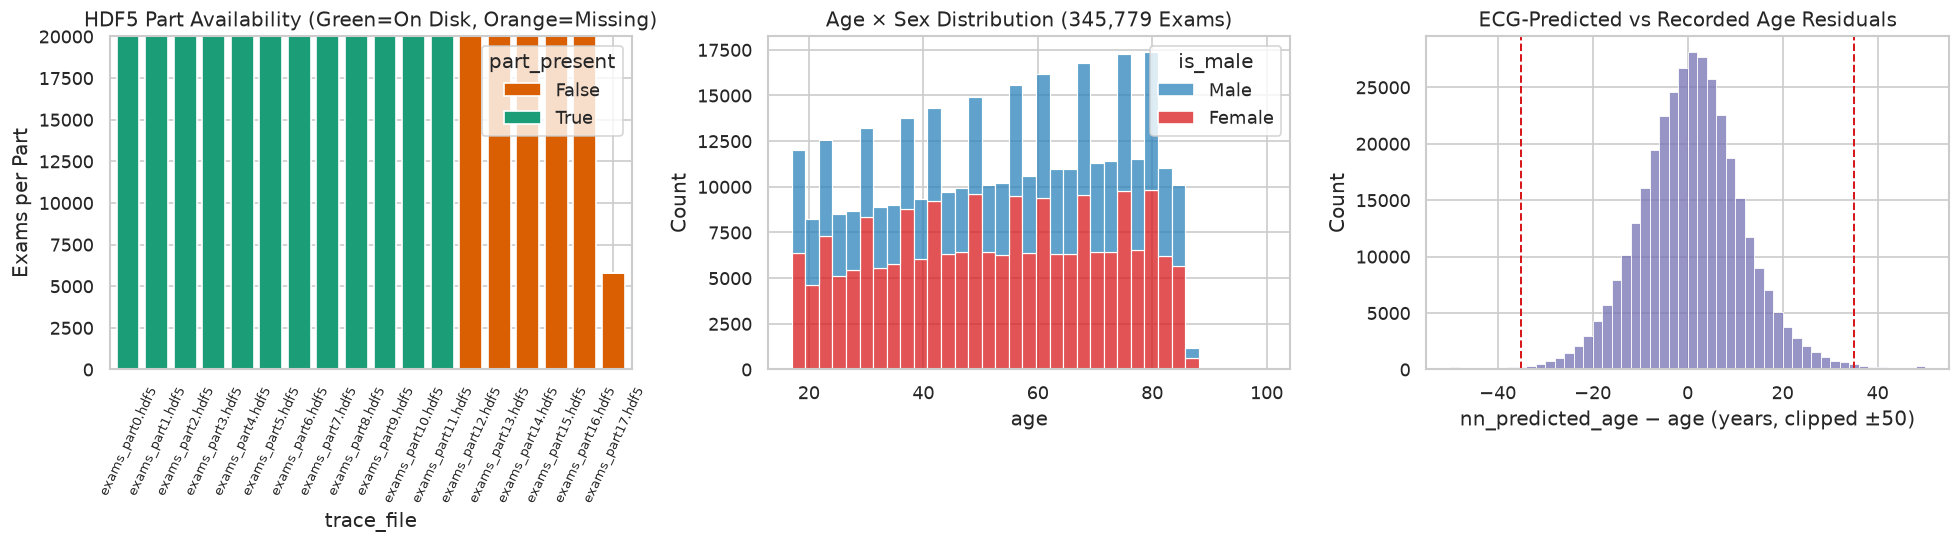

In [1]:
import sys
import warnings
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "code15" / "quality" / "error_labels.csv.gz").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate code15/quality/error_labels.csv.gz from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from code15 import CODE15Dataset

CODE15_DIR = REPO_ROOT / "code15"
DATA_DIR = CODE15_DIR / "data"
QUALITY_DIR = CODE15_DIR / "quality"
LEADS = CODE15Dataset.LEADS
LABEL_COLS = CODE15Dataset.LABEL_COLS

df = pd.read_csv(DATA_DIR / "exams.csv")
df.columns = df.columns.str.strip()
err_df = pd.read_csv(QUALITY_DIR / "error_labels.csv.gz", index_col="exam_id")

present_parts = {p.name for p in DATA_DIR.glob("exams_part*.hdf5")}
df["part_present"] = df["trace_file"].isin(present_parts)

print(f"Total exams in exams.csv  : {len(df):,} | unique patients: {df['patient_id'].nunique():,}")
print(f"Present HDF5 parts on disk: {len(present_parts)} / 18 ({df['part_present'].sum():,} exams readable)")
print(f"Missing survival (death/timey): {int(err_df['err_meta_missing_survival'].sum()):,} ({err_df['err_meta_missing_survival'].mean()*100:.1f}%)")
print(f"Longitudinal patient demo conflicts: {int(err_df['err_tbl_longitudinal_demo_conflict'].sum()):,}")
print(f"|age - nn_predicted_age| > 35 yr   : {int(err_df['err_age_nn_discrepancy_gt35'].sum()):,}")

fig, axes = plt.subplots(1, 3, figsize=(16.5, 4.7))

part_vc = df.groupby(["trace_file", "part_present"]).size().unstack(fill_value=0)
part_vc = part_vc.loc[sorted(part_vc.index, key=lambda s: int(s.replace("exams_part", "").replace(".hdf5", "")))]
part_vc.plot(kind="bar", stacked=True, color={True: "#1b9e77", False: "#d95f02"}, ax=axes[0], width=0.8)
axes[0].set_title("HDF5 Part Availability (Green=On Disk, Orange=Missing)")
axes[0].set_ylabel("Exams per Part")
axes[0].tick_params(axis="x", rotation=65, labelsize=7.5)

sns.histplot(data=df, x="age", hue=df["is_male"].map({True: "Male", False: "Female"}), bins=35, multiple="stack", palette=["#2b83ba", "#d7191c"], ax=axes[1])
axes[1].set_title("Age × Sex Distribution (345,779 Exams)")

age_err = (df["nn_predicted_age"] - df["age"]).dropna()
sns.histplot(age_err.clip(-50, 50), bins=50, color="#7570b3", ax=axes[2])
axes[2].axvline(-35, color="#d7191c", ls="--", lw=1.2); axes[2].axvline(35, color="#d7191c", ls="--", lw=1.2)
axes[2].set_xlabel("nn_predicted_age − age (years, clipped ±50)")
axes[2].set_title("ECG-Predicted vs Recorded Age Residuals")

plt.tight_layout()
plt.show()